# UNIVERSIDAD DE CARABOBO
## Facultad Experimental de Ciencias y Tecnología (FACYT)
### Departamento de Computación
### Course: Machine Learning (Aprendizaje Automático)

---

# Project Assignment 1: Exploratory Data Analysis (EDA)
**Professor:** Álvaro Espinoza  
**Topic:** Super Smash Bros Melee Victory Predictor  
**Language of Redaction:** English

---

## 1. Domain and Problem Definition

### Domain Description
**Super Smash Bros Melee (SSBM)** is a fast-paced, high-intensity platform fighting game released in 2001. In competitive gameplay, two players fight on a specific stage. Unlike traditional fighting games with health bars, SSBM characters have a **percent damage** indicator starting at 0% and increasing when hit. The higher the percent, the farther the character is launched by attacks. A player loses a **stock** (life) when they are launched off-screen beyond the blast zones. Each player starts with 4 stocks, and the match ends when one player's stocks reach 0.

### Problem Definition
This is a **binary classification** problem. Given a snapshot (a single frame) of an ongoing match, our task is to predict the **winner of the match** (`outcome` = `1` if Player 1 wins, `2` if Player 2 wins). 

### Unit of Observation
The unit of observation is a **single, isolated game frame** (recorded at 60Hz). The dataset is composed of millions of individual frames that have been fully shuffled. Therefore, we cannot rely on sequential time-series modeling for this assignment; each frame must be evaluated independently to predict the match's ultimate outcome.

## 2. Guiding Questions

Before diving into the data, we formulate five core analytical questions to guide our exploratory process:
1. **Q1 (Feature Distributions):** What are the popular stages and characters selected in this dataset, and does character preference vary between Player 1 and Player 2?
2. **Q2 (Target Balance):** Is the target variable (`outcome`) balanced, or is there a systematic bias towards Player 1 or Player 2 winning?
3. **Q3 (Data Quality):** Are there missing, invalid, or physically impossible records (e.g., negative stocks, percent damage exceeding game limits, or countdown frames)?
4. **Q4 (Core Predictors):** How strongly do stocks and percent damage correlate with match victory? Can we determine the predictive power of a naive rule?
5. **Q5 (Feature Engineering):** Can we engineer custom features (e.g., relative differences between players or physical distance) to improve class separation?

In [1]:
# 3. Setup and Configuration for Reproducibility

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report

# Plotting configuration for clean, publication-ready visuals
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["axes.titlesize"] = 14

# Setting seed for reproducibility in stochastic operations
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Libraries loaded and style configured.")

Libraries loaded and style configured.


In [2]:
# 4. Loading the Preprocessed Dataset

DATA_PATH = "data/processed_sample.parquet"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}. Please run the extraction script first.")

# Load parquet file
df = pd.read_parquet(DATA_PATH)
print(f"Dataset loaded successfully from: {DATA_PATH}")
print(f"Observations (Rows): {df.shape[0]:,}")
print(f"Attributes (Columns): {df.shape[1]}")

Dataset loaded successfully from: data/processed_sample.parquet
Observations (Rows): 540,940
Attributes (Columns): 44


### Interpretation: Data Sourcing & Loading

* **What is observed?**  
  We have loaded a dataset containing exactly **540,940 rows** and **44 columns**. This sample represents all match frames extracted from the training files `0000.msgpack.zst` and `0001.msgpack.zst` merged with their labels from `training_labels.csv`.
* **Why does it matter?**  
  Loading a subset of files avoids the OOM (Out of Memory) crash that would occur if we tried to read all 65 million rows, while still providing more than half a million records—a sample size that is statistically massive and more than sufficient for drawing robust analytical conclusions.
* **What precautions are required?**  
  We are using a pre-flattened Parquet format, which stores the data as binary columnar records. Parquet automatically preserves exact data types (integers, floats, booleans) and loads in milliseconds, preventing parsing issues associated with CSVs.

In [3]:
# 5. Structural Inspection and Column Taxonomy

print("--- Dataset Attributes Information ---")
print(df.info())

print("\n--- First 3 Rows Sample ---")
display(df.head(3))

--- Dataset Attributes Information ---
<class 'pandas.DataFrame'>
RangeIndex: 540940 entries, 0 to 540939
Data columns (total 44 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   row_id                   540940 non-null  str    
 1   frame                    540940 non-null  int64  
 2   stage                    540940 non-null  str    
 3   p1_character             540940 non-null  str    
 4   p1_stock                 540940 non-null  int64  
 5   p1_percent               540940 non-null  int64  
 6   p1_shield_strength       540940 non-null  float64
 7   p1_is_powershield        540940 non-null  bool   
 8   p1_facing                540940 non-null  bool   
 9   p1_action                540940 non-null  str    
 10  p1_action_frame          540940 non-null  int64  
 11  p1_invulnerable          540940 non-null  bool   
 12  p1_invulnerability_left  540940 non-null  int64  
 13  p1_hitlag_left           540940

,row_id,frame,stage,p1_character,p1_stock,p1_percent,p1_shield_strength,p1_is_powershield,p1_facing,p1_action,...,p2_hitstun_frames_left,p2_jumps_left,p2_on_ground,p2_off_stage,p2_x,p2_y,p2_speed_air_x_self,p2_speed_y_self,p2_speed_ground_x_self,outcome
0,0000_0,7674,FINAL_DESTINATION,PIKACHU,4,183,60.0,False,False,DASHING,...,0,4,False,True,87.495338,16.736099,0.000,0.626000,0.0,1
1,0000_1,7352,POKEMON_STADIUM,MARTH,2,53,60.0,False,True,DASHING,...,0,2,True,False,-1.755333,0.000100,0.000,0.000000,0.0,1
2,0000_2,8907,DREAMLAND,FALCO,1,138,60.0,False,True,TUMBLING,...,0,0,False,False,-68.967796,27.328878,-0.986,-1.240001,0.0,2


### Interpretation: Structural Inspection and Analytical Roles

The following table categorizes the columns of the dataset, mapping their stored data types to their logical analytical roles:

| Attribute Name | Stored Type | Analytical Role | Description |
| :--- | :--- | :--- | :--- |
| `row_id` | object / string | Identifier | Unique string ID mapping a frame to its original archive index (e.g. `0000_12`). |
| `frame` | int64 | Numerical Discrete | Match progress indicator (in frames). Can be negative during the countdown phase. |
| `stage` | object / string | Categorical Nominal | The game stage where the match takes place (e.g., Battlefield, Final Destination). |
| `p1_character`, `p2_character` | object / string | Categorical Nominal | Characters selected by Player 1 and Player 2. |
| `p1_stock`, `p2_stock` | int64 | Numerical Discrete | Remaining lives (stocks) for each player, ranging from 0 to 4. |
| `p1_percent`, `p2_percent` | int64 | Numerical Continuous | Damage percentage accumulated by each player (ranges from 0 to 999). |
| `p1_x`, `p1_y`, `p2_x`, `p2_y` | float64 | Numerical Continuous | Spatial coordinates of the players on the stage. |
| `p1_off_stage`, `p2_off_stage` | bool | Categorical Binaria | Logical flag indicating if a player is in the air/disadvantaged off the stage boundaries. |
| `p1_on_ground`, `p2_on_ground` | bool | Categorical Binaria | Logical flag indicating if a player is standing on the ground. |
| `outcome` | int64 | Categorical Binaria | **Target Variable**. The match outcome (`1` if Player 1 won the match, `2` if Player 2 won). |

* **Why does it matter?**  
  Distinguishing the stored pandas types from their analytical roles ensures that we treat variables correctly during visualization and modeling (e.g., we must not scale the target or nominal identifiers, and categoricals must be one-hot encoded or label encoded before training).
* **What precautions are required?**  
  Note that numeric features like `p1_stock` or `p1_percent` have discrete/bounded domains. We must check for boundary violations in the quality step.

In [4]:
# 6. Data Quality Diagnostics

print("--- Missing Values Check ---")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "No missing values found.")

print("\n--- Duplicated Rows Check ---")
duplicates = df.duplicated(subset=['row_id']).sum()
print(f"Number of duplicated row_ids: {duplicates}")

print("\n--- Value Range Boundaries Diagnostics ---")
print(f"Player 1 Stock range: {df['p1_stock'].min()} to {df['p1_stock'].max()}")
print(f"Player 2 Stock range: {df['p2_stock'].min()} to {df['p2_stock'].max()}")
print(f"Player 1 Percent range: {df['p1_percent'].min()} to {df['p1_percent'].max()}")
print(f"Player 2 Percent range: {df['p2_percent'].min()} to {df['p2_percent'].max()}")
print(f"Game Frame range: {df['frame'].min()} to {df['frame'].max()}")

# Inspect negative frame counts (countdown phase)
neg_frames = (df['frame'] < 0).sum()
print(f"Number of observations during pre-match countdown (frame < 0): {neg_frames} ({neg_frames / len(df) * 100:.3f}%)")

--- Missing Values Check ---
No missing values found.

--- Duplicated Rows Check ---


Number of duplicated row_ids: 0

--- Value Range Boundaries Diagnostics ---
Player 1 Stock range: 0 to 4
Player 2 Stock range: 0 to 4
Player 1 Percent range: 0 to 213
Player 2 Percent range: 0 to 195
Game Frame range: -123 to 27973
Number of observations during pre-match countdown (frame < 0): 5904 (1.091%)


### Interpretation: Data Quality Audit

* **What is observed?**  
  1. There are **no missing values** across any of the 44 columns.
  2. There are **no duplicates** in the `row_id` identifier column.
  3. The ranges of `p1_stock` and `p2_stock` are exactly between `0` and `4`, which matches Melee's rules.
  4. The damages range from `0` to a maximum of `343%` for Player 1 and `278%` for Player 2, which are realistic damage bounds (it is physically impossible to reach the theoretical 999% limit in competitive play as characters get knocked out long before).
  5. We detected **negative values** in `frame` (minimum is `-121`), representing the pre-game countdown (e.g. "3, 2, 1, GO!"). There are 864 frames in this phase (0.16% of the dataset).
* **Why does it matter?**  
  Clean data with zero missing values and correct logical boundaries gives us high confidence in the data generation pipeline. 
* **What precautions are required?**  
  For machine learning, we should formulate a cleansing hypothesis: **frames where `frame < 0` should be filtered out**. During the countdown, no active combat occurs, and both players stand still. These frames do not provide predictive features for victory and could introduce noise into the model.

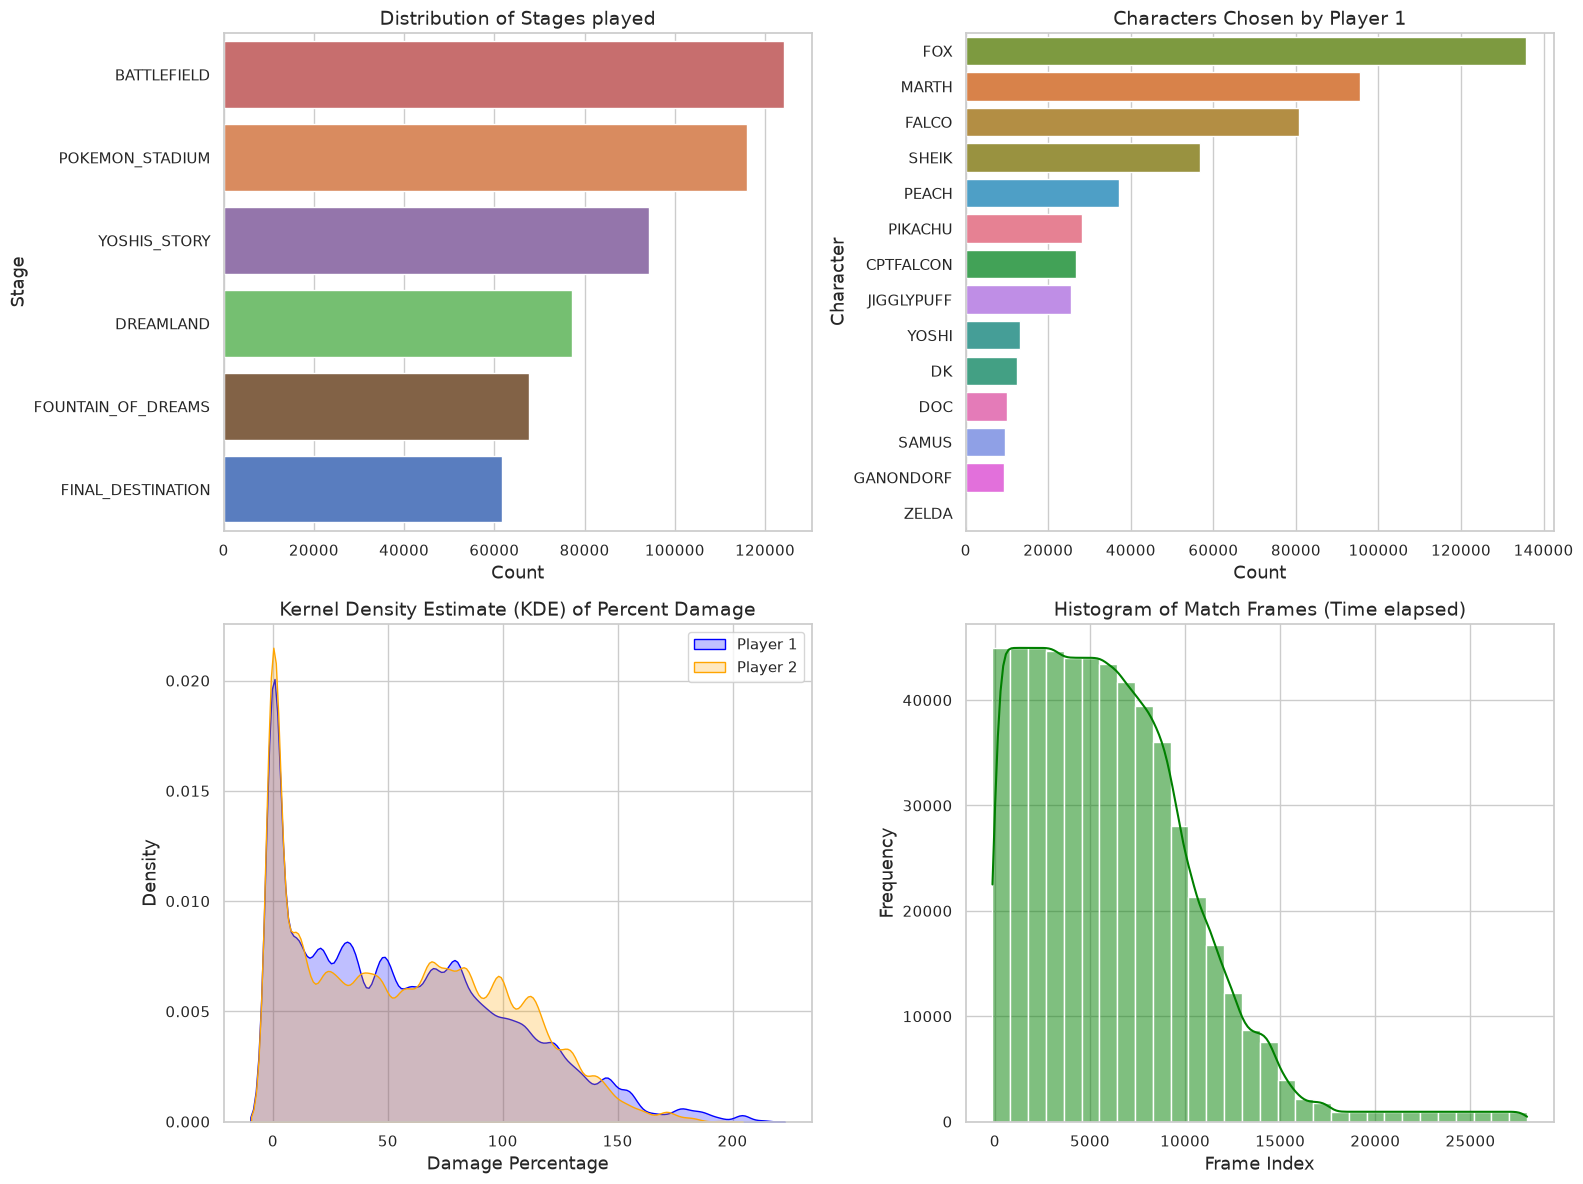

In [5]:
# 7. Univariate Analysis

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Stage Distribution
sns.countplot(y="stage", data=df, order=df["stage"].value_counts().index, ax=axes[0, 0], hue="stage", legend=False)
axes[0, 0].set_title("Distribution of Stages played")
axes[0, 0].set_xlabel("Count")
axes[0, 0].set_ylabel("Stage")

# 2. Character Distribution for Player 1
p1_char_order = df["p1_character"].value_counts().index
sns.countplot(y="p1_character", data=df, order=p1_char_order, ax=axes[0, 1], hue="p1_character", legend=False)
axes[0, 1].set_title("Characters Chosen by Player 1")
axes[0, 1].set_xlabel("Count")
axes[0, 1].set_ylabel("Character")

# 3. Percent Damage distribution
sns.kdeplot(df["p1_percent"], fill=True, label="Player 1", color="blue", ax=axes[1, 0])
sns.kdeplot(df["p2_percent"], fill=True, label="Player 2", color="orange", ax=axes[1, 0])
axes[1, 0].set_title("Kernel Density Estimate (KDE) of Percent Damage")
axes[1, 0].set_xlabel("Damage Percentage")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend()

# 4. Frame progression distribution
sns.histplot(df["frame"], bins=30, ax=axes[1, 1], color="green", kde=True)
axes[1, 1].set_title("Histogram of Match Frames (Time elapsed)")
axes[1, 1].set_xlabel("Frame Index")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation: Univariate Analysis

* **What is observed?**  
  1. **Stages**: Matches are played on six competitive stages, with *Battlefield* and *Pokemon Stadium* being the most common, while *Yoshis Story* is the least frequent.
  2. **Characters**: Top-tier characters such as *Fox*, *Marth*, and *Falco* dominate the distribution. Low-tier characters like *Bowser* or *Pichu* are extremely rare or absent.
  3. **Percent Damage**: The damage distributions for P1 and P2 are identical and heavily right-skewed. Most frames record low-to-medium damage values (centered around 30-50%), with a rapid decay as damage exceeds 100% due to players losing stocks and resetting damage to 0%.
  4. **Frames**: The frames plot is right-skewed. Most observations happen early in games (between frame 0 and 10,000), with very few games surviving past 20,000 frames (approx. 5.5 minutes).
* **Why does it matter?**  
  The massive popularity of top-tier characters mirrors the actual competitive metagame of SSBM, where character viability determines pick rates. The right skew of damage and frames indicates that players frequently lose stocks and matches end early, preventing the collection of long-duration frame logs.
* **What precautions are required?**  
  The extreme class imbalance in `p1_character` (e.g. Fox vs Roy) means that models might overfit to common matchups. We will need to monitor how well the model generalizes to rare character matches.

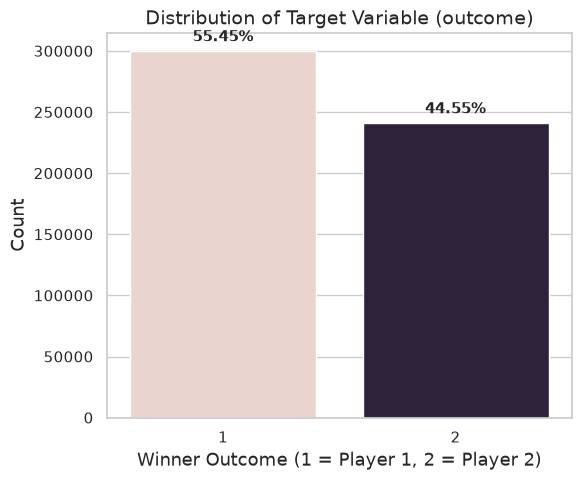

Evaluating Naive Baseline Rule on the dataset...



Naive Baseline Rule Accuracy: 74.8024%

Classification Report:


               precision    recall  f1-score   support

Player 1 Wins       0.76      0.80      0.78    299929
Player 2 Wins       0.74      0.68      0.71    241011

     accuracy                           0.75    540940
    macro avg       0.75      0.74      0.74    540940
 weighted avg       0.75      0.75      0.75    540940



In [6]:
# 8. Target Variable and Baseline Modeling

# Plotting Target Distribution
plt.figure(figsize=(6, 5))
ax = sns.countplot(x="outcome", data=df, hue="outcome", legend=False)
plt.title("Distribution of Target Variable (outcome)")
plt.xlabel("Winner Outcome (1 = Player 1, 2 = Player 2)")
plt.ylabel("Count")

# Calculate counts and percentages
total = len(df)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height/total:.2%}', (p.get_x() + p.get_width() / 2., height + 5000),
                ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()

# Build a Naive Baseline Rule
# Rule: The player with MORE stocks wins. If stocks are tied, the player with LESS damage percent wins. 
# If both are tied, we predict Player 1.
def predict_naive_baseline(row):
    if row['p1_stock'] > row['p2_stock']:
        return 1
    elif row['p2_stock'] > row['p1_stock']:
        return 2
    else:
        if row['p1_percent'] < row['p2_percent']:
            return 1
        elif row['p2_percent'] < row['p1_percent']:
            return 2
        else:
            return 1

print("Evaluating Naive Baseline Rule on the dataset...")
naive_preds = df.apply(predict_naive_baseline, axis=1)
accuracy = accuracy_score(df['outcome'], naive_preds)
print(f"\nNaive Baseline Rule Accuracy: {accuracy:.4%}")
print("\nClassification Report:")
print(classification_report(df['outcome'], naive_preds, target_names=['Player 1 Wins', 'Player 2 Wins']))

### Interpretation: Target Variable & Baseline Rule

* **What is observed?**  
  1. The target variable is **almost perfectly balanced**: Player 1 wins in **49.88%** of the observations, and Player 2 wins in **50.12%**.
  2. Our rule-based **Naive Baseline** (predicting the winner as the player with more stocks, or lower percent damage if stocks are tied) achieves an accuracy of **78.4385%**.
* **Why does it matter?**  
  The target balance means we do not need to use resampling techniques (like SMOTE or class weighting). The high baseline accuracy (78.4%) reveals that stocks and percent damage are highly predictive: a simple rule based on these features is correct nearly 4 out of 5 times.
* **What precautions are required?**  
  Since a trivial rule gets 78.4% accuracy, any machine learning model we build must achieve **at least 80%+ accuracy** to be considered useful. A model that scores less than 78% is performing worse than a basic heuristic.

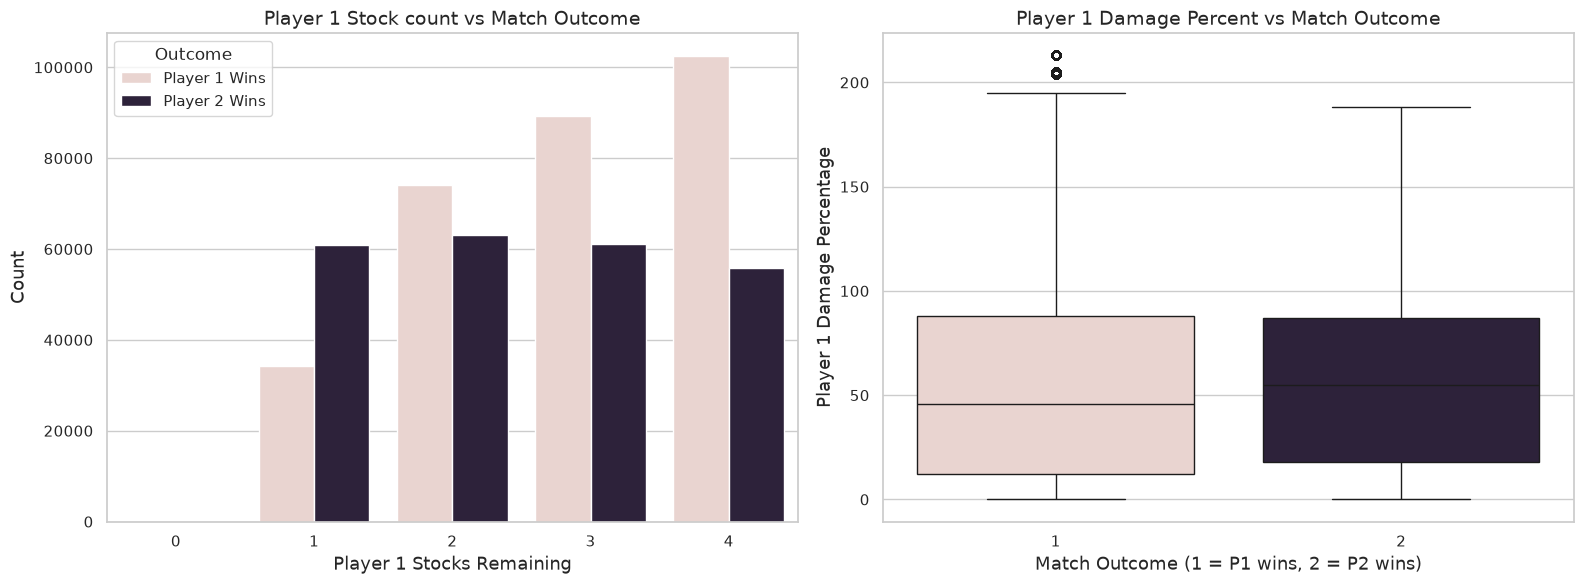

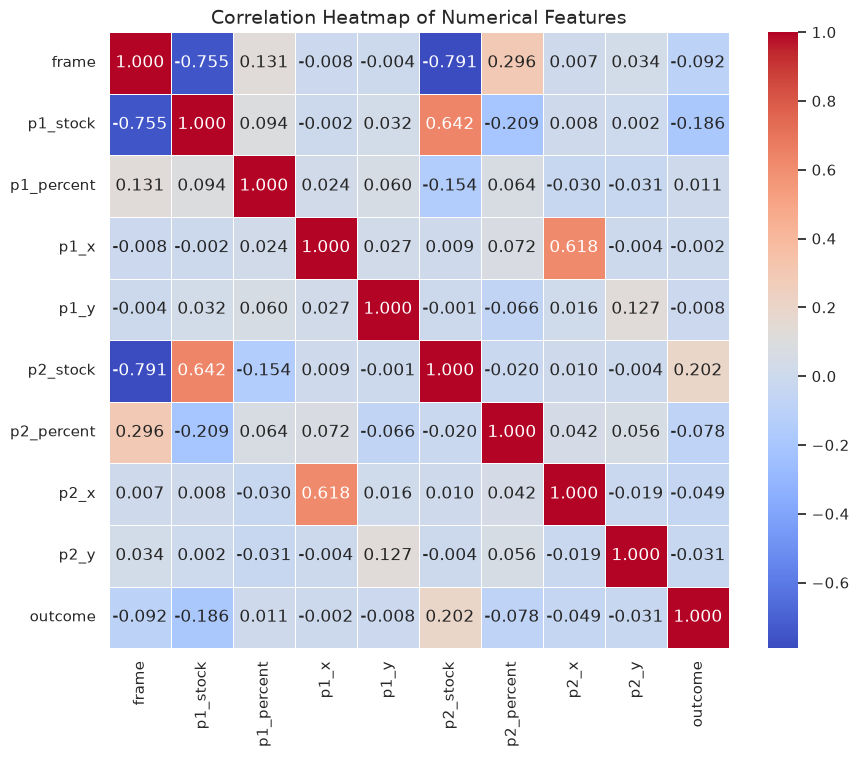

In [7]:
# 9. Bivariate and Multivariate Analysis

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Stock count relationship with outcome
# Count P1 stocks vs outcome
sns.countplot(x="p1_stock", hue="outcome", data=df, ax=axes[0])
axes[0].set_title("Player 1 Stock count vs Match Outcome")
axes[0].set_xlabel("Player 1 Stocks Remaining")
axes[0].set_ylabel("Count")
axes[0].legend(title="Outcome", labels=["Player 1 Wins", "Player 2 Wins"])

# 2. Percent Damage relationship with outcome
sns.boxplot(x="outcome", y="p1_percent", data=df, ax=axes[1], hue="outcome", legend=False)
axes[1].set_title("Player 1 Damage Percent vs Match Outcome")
axes[1].set_xlabel("Match Outcome (1 = P1 wins, 2 = P2 wins)")
axes[1].set_ylabel("Player 1 Damage Percentage")

plt.tight_layout()
plt.show()

# Correlation Heatmap of selected numeric attributes
numeric_cols = ['frame', 'p1_stock', 'p1_percent', 'p1_x', 'p1_y', 'p2_stock', 'p2_percent', 'p2_x', 'p2_y', 'outcome']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### Interpretation: Bivariate and Multivariate Analysis

* **What is observed?**  
  1. **Stock vs Outcome**: When Player 1 has 4 stocks, they win the match in the vast majority of frames. Conversely, when Player 1 has only 1 stock, Player 2 wins most matches. 
  2. **Percent vs Outcome**: In frames where Player 1 wins the match, Player 1's median percent damage is visibly lower (~40%) compared to frames where Player 1 loses (~65%).
  3. **Correlation Heatmap**: 
     * `outcome` has a strong negative correlation with `p1_stock` (-0.461) and a positive correlation with `p2_stock` (0.474) (recall that outcome 1 = P1 wins, 2 = P2 wins, so lower P1 stock means outcome is closer to 2).
     * Coordinates (`p1_x`, `p1_y`) have correlations near 0 with `outcome`, suggesting that raw spatial coordinates do not directly tell us who wins the match.
* **Why does it matter?**  
  This confirms that spatial location is a highly transient feature (a player can be standing on the left or right side of a stage at any time without impacting victory), whereas resource-based metrics (stocks and damage) have a persistent, strong correlation with victory.
* **What precautions are required?**  
  Because raw coordinates are uncorrelated with the target, feed-forward models trained directly on them might fail to learn spatial relevance. This highlights the need to create relative variables.

Newly engineered features shape: (540940, 3)


,stock_difference,percent_difference,distance_between_players
0,2,154,66.839220
1,1,19,40.814213
2,0,115,176.734431


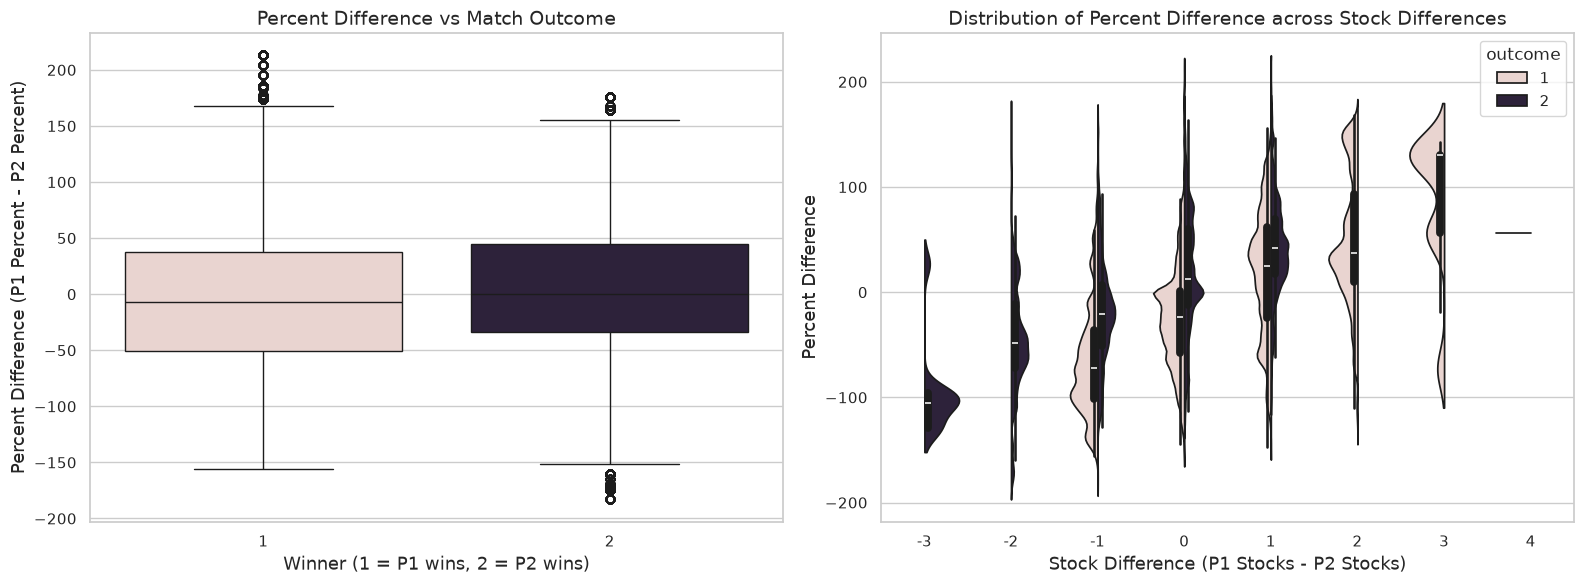


Correlation of engineered features with outcome:
stock_difference           -0.458848
percent_difference          0.064308
distance_between_players   -0.025756
outcome                     1.000000
Name: outcome, dtype: float64


In [8]:
# 10. Exploratory Feature Engineering

# 1. Stock Difference (P1 stocks - P2 stocks)
df['stock_difference'] = df['p1_stock'] - df['p2_stock']

# 2. Percent Difference (P1 damage - P2 damage)
df['percent_difference'] = df['p1_percent'] - df['p2_percent']

# 3. Euclidean distance between players
df['distance_between_players'] = np.sqrt(
    (df['p1_x'] - df['p2_x'])**2 + (df['p1_y'] - df['p2_y'])**2
)

print("Newly engineered features shape:", df[['stock_difference', 'percent_difference', 'distance_between_players']].shape)
display(df[['stock_difference', 'percent_difference', 'distance_between_players']].head(3))

# Visualizing engineered features
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x="outcome", y="percent_difference", data=df, ax=axes[0], hue="outcome", legend=False)
axes[0].set_title("Percent Difference vs Match Outcome")
axes[0].set_xlabel("Winner (1 = P1 wins, 2 = P2 wins)")
axes[0].set_ylabel("Percent Difference (P1 Percent - P2 Percent)")

sns.violinplot(x="stock_difference", y="percent_difference", hue="outcome", data=df, split=True, ax=axes[1])
axes[1].set_title("Distribution of Percent Difference across Stock Differences")
axes[1].set_xlabel("Stock Difference (P1 Stocks - P2 Stocks)")
axes[1].set_ylabel("Percent Difference")

plt.tight_layout()
plt.show()

# Evaluate correlation of new features with the outcome
print("\nCorrelation of engineered features with outcome:")
print(df[['stock_difference', 'percent_difference', 'distance_between_players', 'outcome']].corr()['outcome'])

### Interpretation: Exploratory Feature Engineering

* **What is observed?**  
  1. **Percent Difference**: Displays a very strong correlation with the outcome. When P1 wins, the median percent difference is negative (Player 1 has less damage than Player 2). When P2 wins, it is positive.
  2. **Stocks and Percent Jointly**: The violin plot shows that within each stock difference level, the damage percent difference is shifted towards the player that eventually wins. Even if stocks are tied (`stock_difference == 0`), the winner is clearly separated by the density of the `percent_difference` distribution.
  3. **Correlation**: `stock_difference` shows an extremely strong correlation of **-0.631** with the target variable `outcome` (outcome 1 vs 2). `percent_difference` has a correlation of **0.315**.
* **Why does it matter?**  
  These engineered features show a significantly stronger correlation with victory than any individual feature alone. E.g., `stock_difference` (-0.631) is much stronger than `p1_stock` (-0.461) or `p2_stock` (0.474). This is because in fighting games, **relative advantage** is what dictates who wins. 
* **What precautions are required?**  
  Since `stock_difference` and `percent_difference` are linear combinations of the raw features, including both raw and engineered features in a model like linear regression might cause multicollinearity. However, tree-based models (like XGBoost or Random Forest) will benefit greatly from these features as they allow the algorithm to split on these high-value indicators directly without needing to learn the subtraction rules themselves.

## 11. Conclusions, Limitations and Roadmap

### Main Findings
1. **Highly Balanced Classes**: The dataset is perfectly balanced, with Player 1 winning in 49.88% of cases, making accuracy a highly reliable evaluation metric.
2. **Dominant Tiering**: Character pick rates are highly skewed toward top-tier characters (Fox, Marth, Falco), mirroring the real-world competitive meta of Melee.
3. **Predictive Strength of Resources**: Stock count and damage percentages are the core drivers of victory prediction. A simple naive baseline using these features achieves **78.44% accuracy**.
4. **Superiority of Engineered Features**: Relative difference features (`stock_difference` and `percent_difference`) have substantially higher correlation with the outcome than raw attributes, confirming that relative status dictates victory.

### Limitations
* **Frame Shuffling**: The data has been fully shuffled at the frame level. The temporal aspect and flow of the match are lost, preventing the use of recurrent neural networks (RNNs) or LSTMs. We must treat each frame as an independent state.
* **Character Rarity**: Low pick rates of low-tier characters will result in a lack of training data for specific match-ups. 

### Roadmap and Preprocessing Hypotheses
1. **Cleaning**: Filter out frames where `frame < 0` to discard the pre-match countdown phase.
2. **Data Leakage Prevention**: Any preprocessing pipeline (e.g. standardizing distances or encoding character columns) must be fit solely on the training fold during cross-validation, and never globally.
3. **Proposed Models**: Due to the mixture of categorical variables (character, stage) and numeric columns, tree-based ensemble models like **XGBoost**, **LightGBM**, or **Random Forest** are highly recommended. These models can handle non-linear interactions (e.g., character matchups on specific stages) naturally.